# Constrained matching for crime research

This notebook shows how to prepare agency-level crime records for constrained matching before fitting an outcome model. We begin with fictional treatment records and NIBRS-style offense data, link agencies across sources, build monthly counts, select comparison agencies, and examine pretreatment balance.

All records are synthetic, and the source tables are included with the project. The example illustrates a method used in the research cited below; it does not reproduce the study's empirical data or estimated effects.

Run the cells in order from a fresh kernel. See the [README](README.md) for installation and input details.


In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import coo_array, csr_array, vstack

In [2]:
%matplotlib inline

DATA = Path('data')
OUTPUTS = Path('outputs')
DELTA_RAW, DELTA_LOG = 0.035, 0.05
SOLVER_TIME_LIMIT = 600  # Seconds allowed for each solver pass.

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Look at the source tables

The activation list gives agency names, locations, and dates. The offense file identifies agencies by ID. The crosswalk connects the two. A fourth table records reporting information, including whether an empty month has been verified to contain zero offenses.

These are simplified NIBRS-style records. The example uses `PERS`, `PROP`, and `OTHER` as offense labels; real NIBRS records require a complete mapping from their original offense codes.

In [3]:
# The four input files are included, so this example needs no outside data download.
crosswalk = pd.read_csv(DATA / 'crosswalk.csv', dtype={'agency_id': 'string'})
activations = pd.read_csv(DATA / 'activations.csv')
offenses = pd.read_csv(DATA / 'offenses.csv.xz', dtype={
    'agency_id': 'string', 'incident_id': 'string', 'offense_code': 'string',
})
availability = pd.read_csv(DATA / 'availability.csv', dtype={'agency_id': 'string'})

for label, table in [
    ('Activation list', activations[['agency_name', 'state', 'activation_date']]),
    ('Agency crosswalk', crosswalk[['agency_id', 'agency_name', 'state', 'population']]),
    ('NIBRS-style offense records', offenses),
]:
    display(Markdown(f'**{label}**'))
    display(table.head(3))

**Activation list**

,agency_name,state,activation_date
0,synthetic borough 001 pd,ST_B,2022-02-15
1,synthetic borough 003 pd,ST_A,2020-04-15
2,synthetic borough 004 pd,ST_A,2022-06-15


**Agency crosswalk**

,agency_id,agency_name,state,population
0,SYN0001,Synthetic Borough 001 Police Department,ST_B,61304
1,SYN0002,Synthetic Borough 002 Police Department,ST_A,26655
2,SYN0003,Synthetic Borough 003 Police Department,ST_A,100002


**NIBRS-style offense records**

,agency_id,incident_id,offense_code,incident_date
0,syn0001,0,PERS,2016-01-01
1,syn0001,1,PERS,2016-01-02
2,syn0001,2,PERS,2016-01-03


## 2. Join treatment information to the monthly data

### Connect the names to agency IDs

We standardize the names, then look for a unique match in the same state and within 0.1 degrees in both latitude and longitude. If an agency appears more than once, we keep its earliest valid activation date. Unresolved links stay in `linkage` for review, and any agency implicated in an unresolved link is excluded from matching.

This illustrates the linkage step. Real treatment records need a reviewed crosswalk, including a decision about uncertain and approximate-name matches.

In [4]:
def name_key(name):
    words = re.sub(r'[^A-Z0-9 ]', ' ', str(name).upper()).split()
    return ' '.join('POLICE DEPARTMENT' if word == 'PD' else word for word in words)


crosswalk['agency_id'] = crosswalk.agency_id.str.strip().str.upper()
assert crosswalk.agency_id.notna().all() and crosswalk.agency_id.is_unique
assert crosswalk[['agency_name', 'state', 'county', 'agency_type']].notna().all().all()
assert np.isfinite(crosswalk[['population', 'latitude', 'longitude']]).all().all()
assert (crosswalk.population.gt(0) & crosswalk.latitude.between(-90, 90)
        & crosswalk.longitude.between(-180, 180)).all()
crosswalk['name_key'] = crosswalk.agency_name.map(name_key)

links, uncertain_ids = [], set()
for row in activations.itertuples(index=False):
    same_name = crosswalk.loc[crosswalk.state.eq(row.state)
                              & crosswalk.name_key.eq(name_key(row.agency_name))]
    nearby = same_name.loc[(same_name.latitude - row.latitude).abs().le(.1)
                           & (same_name.longitude - row.longitude).abs().le(.1)]
    date = pd.to_datetime(row.activation_date, errors='coerce')
    resolved = len(nearby) == 1 and pd.notna(date)
    if not resolved:
        # An uncertain treatment identity must not silently become a comparison.
        uncertain_ids.update(same_name.agency_id)
    links.append({'source_row': row.source_row, 'resolved': resolved,
                  'agency_id': nearby.agency_id.iloc[0] if resolved else pd.NA,
                  'activation_date': date if resolved else pd.NaT})

linkage = pd.DataFrame(links)
linked = linkage.loc[linkage.resolved]
first_activation = linked.groupby('agency_id', as_index=False).activation_date.min()
first_activation['activation_month'] = first_activation.activation_date.dt.strftime('%Y-%m')
metadata = crosswalk.drop(columns='name_key').merge(
    first_activation, on='agency_id', how='left', validate='one_to_one',
)
metadata['linkage_uncertain'] = metadata.agency_id.isin(uncertain_ids)
metadata['treatment_status'] = np.where(metadata.activation_month.notna(),
                                       'recorded_activation', 'no_recorded_activation')
metadata.loc[metadata.linkage_uncertain, 'treatment_status'] = 'unresolved_linkage'
print(f'{len(linked)} of {len(linkage)} activation rows linked; '
      f'{len(linkage) - len(linked)} unresolved. Repeated links use the earliest date.')

86 of 87 activation rows linked; 1 unresolved. Repeated links use the earliest date.


### Count offenses and attach activation dates

We remove invalid records and exact duplicates, and set aside conflicting records in `conflicting_offenses`. Different offense codes within the same incident remain separate, so our totals count offenses rather than incidents.

Next, we count offenses by agency and month and attach each agency's activation information. The merge checks ensure that there is one agency record per ID and that the join keeps every monthly row.

A missing month stays missing; a documented zero stays zero. This study's eligibility rule requires at least one retained offense record in every month from January 2016 through December 2022, with no unresolved treatment identity. Even a verified all-offense zero fails this particular rule. A category zero is allowed when other offenses are present. This full-period eligibility screen is separate from the pretreatment windows used for matching.

In [5]:
CODE_MAP = {'PERS': 'person', 'PROP': 'property', 'OTHER': 'other'}
MONTHS = pd.period_range('2016-01', '2022-12', freq='M').astype(str)

records = offenses.copy()
records['agency_id'] = records.agency_id.str.strip().str.upper()
records['offense_code'] = records.offense_code.str.strip().str.upper()
records['incident_date'] = pd.to_datetime(records.incident_date, errors='coerce')
valid = (records.agency_id.isin(metadata.agency_id)
         & records.incident_date.between('2016-01-01', '2022-12-31')
         & records.offense_code.isin(CODE_MAP) & records.incident_id.notna())
rejected_offenses = records.loc[~valid].copy()

# One incident can contain several offenses; keep the original code in the key.
offense_key = ['agency_id', 'incident_id', 'offense_code']
records = records.loc[valid].drop_duplicates(offense_key + ['incident_date'])
conflicting = records.duplicated(offense_key, keep=False)
conflicting_offenses = records.loc[conflicting].copy()
records = records.loc[~conflicting].copy()
records['month'] = records.incident_date.dt.strftime('%Y-%m')
records['outcome'] = records.offense_code.map(CODE_MAP)

monthly = records.groupby(['agency_id', 'month', 'outcome']).size().unstack(fill_value=0)
monthly = monthly.reindex(columns=['person', 'property', 'other'], fill_value=0).reset_index()
monthly.columns.name = None
monthly['all'] = monthly[['person', 'property', 'other']].sum(axis=1)
monthly['source_present'] = True

# Start with every agency-month, including months absent from the offense file.
grid = pd.MultiIndex.from_product([metadata.agency_id, MONTHS],
                                 names=['agency_id', 'month']).to_frame(index=False)
panel = grid.merge(monthly, on=['agency_id', 'month'], how='left', validate='one_to_one')
panel = panel.merge(availability, on=['agency_id', 'month'], how='left', validate='one_to_one')
for column in ['source_present', 'report_received', 'verified_zero']:
    panel[column] = panel[column].eq(True)
assert not (panel.verified_zero & panel.source_present).any(), 'Conflicting zero report.'
# Fill only documented zeros. A month with no source records otherwise stays missing.
panel.loc[panel.verified_zero, ['all', 'person', 'property', 'other']] = 0
source_months = panel.groupby('agency_id').source_present.sum()
metadata['source_months'] = metadata.agency_id.map(source_months)
metadata['continuous_source'] = metadata.source_months.eq(len(MONTHS))
metadata['source_eligible'] = metadata.continuous_source & ~metadata.linkage_uncertain

panel = panel.merge(metadata[['agency_id', 'activation_month', 'treatment_status']],
                    on='agency_id', how='left', validate='many_to_one', indicator=True)
assert len(panel) == len(grid) and panel['_merge'].eq('both').all()
assert not panel.duplicated(['agency_id', 'month']).any()
panel = panel.drop(columns='_merge')

example = linked.iloc[0]
anchor = pd.Period(example.activation_date, freq='M')
example_rows = panel.loc[
    panel.agency_id.eq(example.agency_id)
    & panel.month.between(str(anchor - 2), str(anchor + 1)),
    ['agency_id', 'month', 'all', 'person', 'property', 'activation_month'],
]
display(example_rows.style.format({name: '{:,.0f}' for name in ['all', 'person', 'property']}))
print(f'{len(offenses):,} source offense rows become {len(records):,} retained records.')
print(f'{len(panel):,} agency-months joined; '
      f'{metadata.source_eligible.sum()} of {len(metadata)} agencies pass the eligibility screen.')

,agency_id,month,all,person,property,activation_month
71,SYN0001,2021-12,62,8,39,2022-02
72,SYN0001,2022-01,46,2,31,2022-02
73,SYN0001,2022-02,39,4,22,2022-02
74,SYN0001,2022-03,75,19,47,2022-02


856,321 source offense rows become 856,297 retained records.
20,496 agency-months joined; 242 of 244 agencies pass the eligibility screen.


## 3. Describe agencies before treatment

Treated agencies first activate during 2019–2022. Comparisons have no recorded activation or first activate after December 2022.

For a treated agency activating in month `a`, we describe both agencies in a potential pair using the same 24 calendar months: `a−24` through `a−1`. The comparison uses the treated agency's observation window.

| Characteristic | Raw version | Transformed version |
|---|---|---|
| Population | Population | `log1p(population)` |
| Average all/person/property offenses | Mean monthly count | `log1p(mean count)` |
| Trend in all/person/property offenses | Slope of monthly counts | Slope of `log1p(monthly counts)` |

There are seven characteristics in each version. For a transformed trend, we log each monthly count plus one and then calculate the slope. `feature_values` looks up the same agency characteristics for matching and the later checks.

In [6]:
RAW_FEATURES = ["population", "mean_all", "mean_person", "mean_property",
                "slope_all", "slope_person", "slope_property"]
LOG_FEATURES = ["log_" + name for name in RAW_FEATURES]
EDGE_KEYS = ["treated_id", "comparison_id", "activation_month", "activation_year"]
DELTA_COLUMNS = [f"delta_{scale}_{name}" for scale in ("raw", "log") for name in RAW_FEATURES]

def feature_values(feature_index, ids, anchors, columns):
    keys = pd.MultiIndex.from_arrays([list(ids), list(anchors)],
                                     names=["agency_id", "anchor_month"])
    return feature_index.loc[keys, columns].to_numpy(float)


def engineer_features(panel, metadata):
    eligible = metadata.loc[metadata.source_eligible]
    anchors = sorted(eligible.loc[
        eligible.activation_month.between("2019-01", "2022-12").fillna(False),
        "activation_month"].unique())
    counts = panel.set_index(["agency_id", "month"])
    if not counts.index.is_unique:
        raise ValueError("Expected one row per agency and month.")
    # Center the month index to calculate each linear slope.
    time = np.arange(24, dtype=float) - 11.5
    rows = []
    for anchor in anchors:
        months = pd.period_range(pd.Period(anchor, "M") - 24, periods=24).astype(str)
        for agency in eligible.itertuples(index=False):
            keys = pd.MultiIndex.from_product([[agency.agency_id], months])
            values = counts.reindex(keys)[["all", "person", "property"]].to_numpy(float)
            if not np.isfinite(values).all() or (values < 0).any():
                raise ValueError(f"Incomplete or invalid preperiod: {agency.agency_id}, {anchor}")
            means = values.mean(axis=0)
            slopes = time @ values / (time @ time)
            # For the transformed trend, take logs of monthly counts first.
            log_slopes = time @ np.log1p(values) / (time @ time)
            raw = np.r_[agency.population, means, slopes]
            transformed = np.r_[np.log1p(raw[:4]), log_slopes]
            rows.append([agency.agency_id, anchor, *raw, *transformed])
    return pd.DataFrame(rows, columns=["agency_id", "anchor_month"] + RAW_FEATURES + LOG_FEATURES)

In [7]:
features = engineer_features(panel, metadata)
print(f'{len(features):,} agency-window records prepared from the 24 pretreatment months.')

9,680 agency-window records prepared from the 24 pretreatment months.


### Find eligible comparison agencies

A pair must have the same state and agency type, different counties and coordinates, no more than 250 miles between agencies, and a population ratio no greater than three in either direction.

We also calculate distance using the seven transformed characteristics. Each difference is divided by its month-specific standard deviation (SD), then the standardized differences are combined into a Euclidean distance. Smaller values mean closer pairs; we keep distances of four or less.

The distance SDs use the full source-eligible agency pool. Values are limited to the 1st and 99th percentiles **only when calculating those SDs**. The values used in pair differences remain unchanged. We use sample SDs (`ddof=1`) and linear interpolation for the percentiles.

In [8]:
def build_candidates(metadata, features):
    eligible = metadata.loc[metadata.source_eligible].copy()
    eligible["activation_month"] = eligible.activation_month.astype("string")
    treated = eligible.loc[eligible.activation_month.between("2019-01", "2022-12").fillna(False)]
    controls = eligible.loc[eligible.activation_month.isna() | (eligible.activation_month > "2022-12")]
    f = features.set_index(["agency_id", "anchor_month"])
    if not f.index.is_unique or not np.isfinite(f[RAW_FEATURES + LOG_FEATURES].to_numpy(float)).all():
        raise ValueError("Matching features must be unique and finite.")
    frames, scale_rows = [], []
    for anchor, group in treated.groupby("activation_month", sort=True):
        pool = feature_values(f, eligible.agency_id, [anchor] * len(eligible), LOG_FEATURES)
        low, high = np.quantile(pool, [.01, .99], axis=0, method="linear")
        # Clip only for the SD calculation; pair differences stay unchanged.
        scales = np.clip(pool, low, high).std(axis=0, ddof=1)
        if not np.isfinite(scales).all() or (scales <= 0).any():
            raise ValueError(f"Undefined or zero distance SD at {anchor}.")
        scale_rows.extend(zip([anchor] * 7, LOG_FEATURES, scales))
        c_values = feature_values(f, controls.agency_id, [anchor] * len(controls), RAW_FEATURES + LOG_FEATURES)
        for agency in group.itertuples(index=False):
            t_values = feature_values(f, [agency.agency_id], [anchor], RAW_FEATURES + LOG_FEATURES)[0]
            differences = t_values - c_values
            distance = np.sqrt(((differences[:, 7:] / scales) ** 2).sum(axis=1))
            lat1, lat2 = np.radians(agency.latitude), np.radians(controls.latitude.to_numpy())
            longitude_gap = np.radians(controls.longitude.to_numpy()) - np.radians(agency.longitude)
            h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(longitude_gap / 2) ** 2
            miles = 2 * 3958.7613 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))
            ratio = np.maximum(agency.population / controls.population.to_numpy(),
                               controls.population.to_numpy() / agency.population)
            allowed = ((controls.state.to_numpy() == agency.state)
                       & (controls.agency_type.to_numpy() == agency.agency_type)
                       & (controls.county.to_numpy() != agency.county)
                       & ((controls.latitude.to_numpy() != agency.latitude)
                          | (controls.longitude.to_numpy() != agency.longitude))
                       & (miles <= 250) & (ratio <= 3) & (distance <= 4))
            frame = pd.DataFrame({"treated_id": agency.agency_id,
                "comparison_id": controls.agency_id.to_numpy(), "activation_month": anchor,
                "activation_year": int(anchor[:4]), "geo_miles": miles,
                "population_ratio": ratio, "distance": distance})
            frame[DELTA_COLUMNS] = differences
            frames.append(frame.loc[allowed])
    columns = EDGE_KEYS + ["geo_miles", "population_ratio", "distance"] + DELTA_COLUMNS
    edges = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=columns)
    return edges, pd.DataFrame(scale_rows, columns=["anchor_month", "feature", "scale"])

In [9]:
edges, distance_scales = build_candidates(metadata, features)
if edges.empty:
    raise ValueError('No candidate pairs meet the eligibility rules. Review the inputs and design.')
print(f'{len(edges):,} eligible candidate pairs for {edges.treated_id.nunique()} treated agencies.')

1,630 eligible candidate pairs for 79 treated agencies.


## 4. Choose the comparison agencies

We solve one matching problem for each activation year. The first pass finds the largest number of pairs that meets the rules. The second keeps that count fixed and minimizes total distance. Each agency can be used once within a year; comparisons can be used again in another year.

The selected groups must also be close on average. For every characteristic, the allowed absolute mean gap is 0.035 reference SDs in the raw version and 0.05 in the transformed version. These SDs come from the distinct treated agencies with at least one eligible candidate in that year, each measured at its own activation month. They stay fixed during selection and differ from the SDs used for pair distance.

The solver uses one yes-or-no decision per candidate pair. The constraints prevent an agency from being assigned more than once within a year and enforce the fourteen balance limits. Both passes must establish an optimal solution; reaching the time limit is not treated as a completed match.

In [10]:
def select_matches(edges, features, delta_raw=.035, delta_log=.05, time_limit=600):
    if (not np.isfinite([delta_raw, delta_log, time_limit]).all()
            or min(delta_raw, delta_log) < 0 or time_limit <= 0):
        raise ValueError("Tolerances must be nonnegative and time_limit positive.")
    f = features.set_index(["agency_id", "anchor_month"])
    tolerance = np.array([delta_raw] * 7 + [delta_log] * 7)
    selected, scale_frames, solver_rows = [], [], []
    if edges.duplicated(EDGE_KEYS).any():
        raise ValueError("Candidate pairs must be unique.")
    for year, group in edges.groupby("activation_year", sort=True):
        group = group.sort_values(EDGE_KEYS).reset_index(drop=True)
        treated = group[["treated_id", "activation_month"]].drop_duplicates()
        values = feature_values(f, treated.treated_id, treated.activation_month, RAW_FEATURES + LOG_FEATURES)
        if len(values) < 2:
            raise ValueError(f"Year {year}: at least two matchable treated agencies are needed.")
        sd = values.std(axis=0, ddof=1)
        if not np.isfinite(sd).all() or (sd <= 0).any():
            raise ValueError(f"Year {year}: undefined or zero balance SD.")
        scale_frames.append(pd.DataFrame({"activation_year": year,
            "representation": ["raw"] * 7 + ["log"] * 7,
            "feature": RAW_FEATURES * 2, "scale": sd}))
        t_codes, t_ids = pd.factorize(group.treated_id, sort=True)
        c_codes, c_ids = pd.factorize(group.comparison_id, sort=True)
        n, n_agencies = len(group), len(t_ids) + len(c_ids)
        # Each column is a candidate pair. Each agency can enter at most one pair.
        assignments = coo_array((np.ones(2 * n),
            (np.r_[t_codes, c_codes + len(t_ids)], np.tile(np.arange(n), 2))),
            shape=(n_agencies, n)).tocsr()
        difference = group[DELTA_COLUMNS].to_numpy(float).T / sd[:, None]
        # Bound the total gap by tolerance times the number of selected pairs.
        # Use both signs because the limit applies to the absolute mean gap.
        matrix = vstack([assignments, csr_array(difference - tolerance[:, None]),
                         csr_array(-difference - tolerance[:, None])], format="csc")
        upper = np.r_[np.ones(n_agencies), np.zeros(28)]
        constraints = [LinearConstraint(matrix, -np.inf, upper)]

        def solve(objective, stage):
            # SciPy forwards the one-thread option to HiGHS.
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore", message=r"Unrecognized options detected:.*threads.*",
                                        category=RuntimeWarning)
                result = milp(c=objective, integrality=np.ones(n, dtype=int),
                    bounds=Bounds(0, 1), constraints=constraints,
                    options={"time_limit": time_limit, "mip_rel_gap": 0., "threads": 1})
            if result.status != 0 or result.x is None:
                raise RuntimeError(f"Year {year}, {stage}: optimality was not established. {result.message}")
            z = np.rint(result.x).astype(int)
            if (np.max(np.abs(result.x - z)) > 1e-6 or (z < 0).any() or (z > 1).any()
                    or (matrix @ z > upper + 1e-6).any()):
                raise AssertionError("The solver result failed the feasibility check.")
            solver_rows.append({"activation_year": year, "pass": stage,
                                "status": result.status, "n_matches": int(z.sum()),
                                "objective": result.fun, "gap": result.mip_gap})
            return z

        z = solve(-np.ones(n), "cardinality")
        maximum = int(z.sum())
        # Hold the maximum pair count fixed, then find the closest assignment.
        constraints.append(LinearConstraint(np.ones((1, n)), maximum, maximum))
        z = solve(group.distance.to_numpy(float), "distance")
        if z.sum() != maximum:
            raise AssertionError("The second pass changed the maximum pair count.")
        chosen = group.loc[z == 1].copy()
        if len(chosen):
            # Recheck the selected means directly from agency features.
            t = feature_values(f, chosen.treated_id, chosen.activation_month, RAW_FEATURES + LOG_FEATURES)
            c = feature_values(f, chosen.comparison_id, chosen.activation_month, RAW_FEATURES + LOG_FEATURES)
            if (np.abs((t - c).mean(axis=0) / sd) > tolerance + 1e-6).any():
                raise AssertionError("Selected pairs failed the independent balance check.")
        selected.append(chosen)
    matches = pd.concat(selected, ignore_index=True) if selected else edges.copy()
    scales = pd.concat(scale_frames, ignore_index=True) if scale_frames else pd.DataFrame(
        columns=["activation_year", "representation", "feature", "scale"])
    return matches, scales, pd.DataFrame(solver_rows)

In [11]:
matches, balance_scales, solver_log = select_matches(
    edges, features, delta_raw=DELTA_RAW, delta_log=DELTA_LOG,
    time_limit=SOLVER_TIME_LIMIT,
)
for role in ['treated_id', 'comparison_id']:
    assert not matches.duplicated(['activation_year', role]).any()

treated = metadata.loc[
    metadata.source_eligible & metadata.activation_month.between('2019-01', '2022-12').fillna(False)
].copy()
treated['activation_year'] = treated.activation_month.str[:4].astype(int)
treated['has_candidates'] = treated.agency_id.isin(edges.treated_id)
treated['matched'] = treated.agency_id.isin(matches.treated_id)
retention = treated.groupby('activation_year').agg(
    eligible_treated=('agency_id', 'size'), with_candidates=('has_candidates', 'sum'),
    matched=('matched', 'sum'),
)
display(retention.rename(columns={'eligible_treated': 'Eligible treated',
    'with_candidates': 'With candidates', 'matched': 'Matched'}).rename_axis('Activation year'))
print(f'{len(matches)} pairs selected; all {len(solver_log)} solver passes reached optimal status.')

,Eligible treated,With candidates,Matched
Activation year,,,
2019,21,19,19
2020,21,20,20
2021,21,20,20
2022,21,20,20


79 pairs selected; all 8 solver passes reached optimal status.


## 5. Check balance before and after matching

Before matching, each treated agency **with an eligible candidate** gets equal weight, and we share its comparison weight equally among its candidates. After matching, each selected pair gets equal weight. The annual reference SDs stay fixed. Agencies without candidates appear in the retention table above, but are not part of this balance comparison.

Smaller bars mean closer group averages. Each bar is the largest absolute standardized gap across the four activation years, so a poorly balanced year stays visible. The largest gap can come from different years before and after matching. For example, 0.10 means the group means differ by one tenth of a reference SD.

The chart shows the seven raw characteristics. The code also checks every annual limit for both the raw and transformed versions, using the selected agencies' features directly.

The distance medians summarize candidate and selected pairs, with one observation per pair. The balance chart uses the agency weights described above.

All 56 annual feature-balance checks passed.
Median pair distance: 2.61 among candidates; 1.77 among selected pairs.


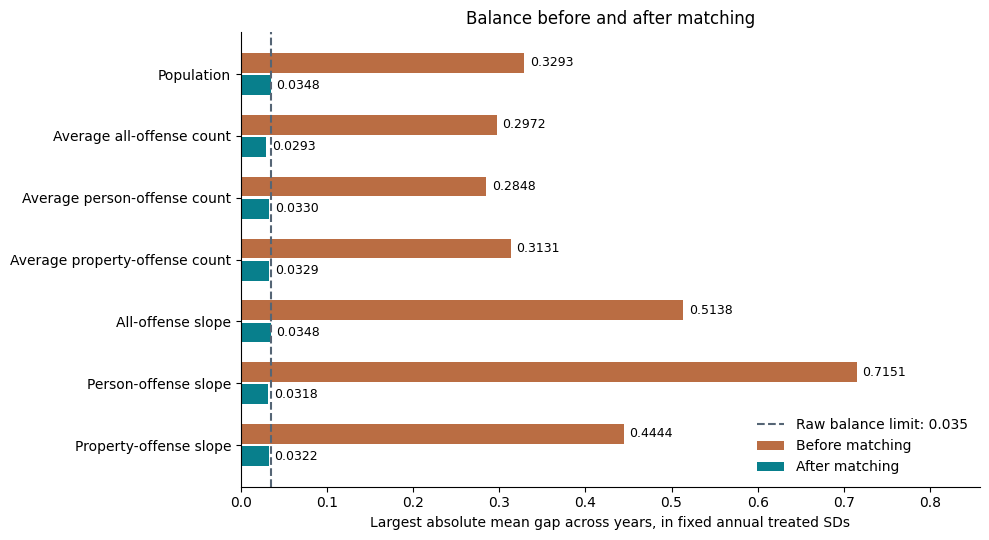

In [12]:
feature_index = features.set_index(['agency_id', 'anchor_month'])
feature_names = RAW_FEATURES + LOG_FEATURES


def balance_report(selected):
    """Keep the reference group and SD fixed when comparing different samples."""
    rows = []
    for year, candidates in edges.groupby('activation_year'):
        anchors = candidates[['treated_id', 'activation_month']].drop_duplicates()
        before_t = feature_values(feature_index, anchors.treated_id,
                                  anchors.activation_month, feature_names)
        candidate_c = feature_values(feature_index, candidates.comparison_id,
                                     candidates.activation_month, feature_names)
        # Average within each treated agency's candidate set before averaging agencies.
        before_c = pd.DataFrame(candidate_c, index=candidates.treated_id).groupby(level=0).mean()
        chosen = selected.loc[selected.activation_year.eq(year)]
        after_t = feature_values(feature_index, chosen.treated_id,
                                 chosen.activation_month, feature_names)
        after_c = feature_values(feature_index, chosen.comparison_id,
                                 chosen.activation_month, feature_names)
        scale = before_t.std(axis=0, ddof=1)
        reported = balance_scales.loc[balance_scales.activation_year.eq(year)].set_index(
            ['representation', 'feature']).reindex(
                pd.MultiIndex.from_product([['raw', 'log'], RAW_FEATURES]))['scale'].to_numpy()
        assert np.isfinite(scale).all() and (scale > 0).all()
        assert np.allclose(scale, reported, rtol=1e-10, atol=1e-12)
        before = (before_t.mean(axis=0) - before_c.mean(axis=0).to_numpy()) / scale
        after = ((after_t.mean(axis=0) - after_c.mean(axis=0)) / scale
                 if len(chosen) else np.full(len(feature_names), np.nan))
        rows.append(pd.DataFrame({
            'activation_year': year, 'representation': ['raw'] * 7 + ['log'] * 7,
            'feature': RAW_FEATURES * 2, 'before': before, 'after': after,
            'limit': [DELTA_RAW] * 7 + [DELTA_LOG] * 7,
        }))
    return pd.concat(rows, ignore_index=True)


balance = balance_report(matches)
assert balance.after.notna().all()
assert (balance.after.abs() <= balance.limit + 1e-7).all()
print(f'All {len(balance)} annual feature-balance checks passed.')
print(f'Median pair distance: {edges.distance.median():.2f} among candidates; '
      f'{matches.distance.median():.2f} among selected pairs.')

# Use each feature's largest annual gap, so one well-balanced year cannot hide another.
worst = balance.loc[balance.representation.eq('raw')].groupby('feature')[
    ['before', 'after']].agg(lambda x: x.abs().max()).reindex(RAW_FEATURES)
labels = ['Population', 'Average all-offense count', 'Average person-offense count',
          'Average property-offense count', 'All-offense slope',
          'Person-offense slope', 'Property-offense slope']
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(labels))
for stage, offset, color in [('before', -.18, '#BA6D43'), ('after', .18, '#087F8C')]:
    bars = ax.barh(y + offset, worst[stage], height=.32, color=color,
                   label=f'{stage.capitalize()} matching')
    ax.bar_label(bars, fmt='%.4f', padding=4, fontsize=9)
ax.axvline(DELTA_RAW, color='#556575', ls='--', label=f'Raw balance limit: {DELTA_RAW}')
ax.set(yticks=y, yticklabels=labels, xlim=(0, worst.to_numpy().max() * 1.2),
       xlabel='Largest absolute mean gap across years, in fixed annual treated SDs',
       title='Balance before and after matching')
ax.invert_yaxis()
ax.legend(loc='lower right', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Compare pretreatment histories

The figure shows monthly property-offense counts for the 2019 activation cohort. Thin lines represent monthly averages; thick lines show fitted linear trends. **Both panels use pretreatment data.** Here, “after” means *after matching*, not after treatment.

The table compares the groups' 24-month average levels and fitted slopes, which are among the characteristics used to select matches. It does not measure similarity at every individual month.


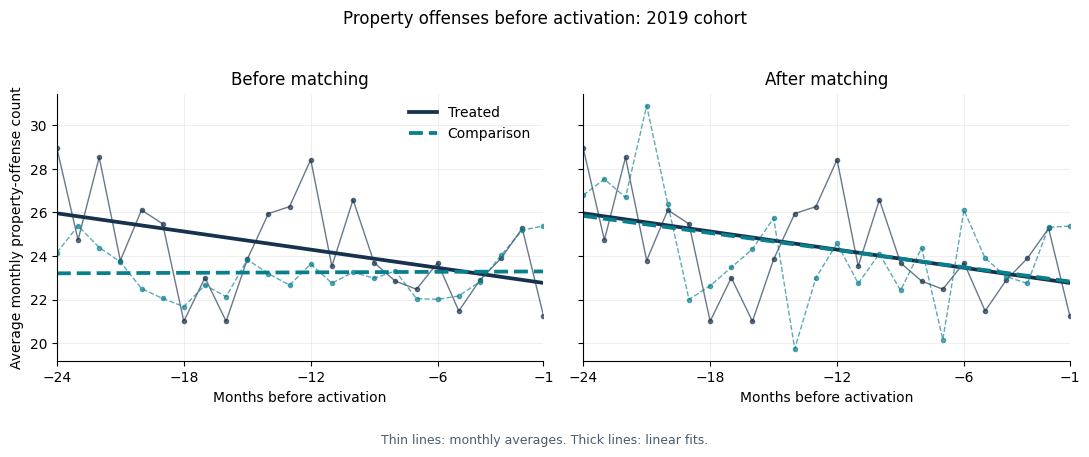

,Before,After,Change
Gap in 24-month mean (offenses),1.1144,0.0263,Closer
Gap in slope (offenses per month),0.1427,0.0080,Closer


In [13]:
HISTORY_YEAR = 2019
monthly = panel.set_index(['agency_id', 'month'])
event_months = np.arange(-24, 0)
centered_months = event_months - event_months.mean()


def average_history(pairs, role):
    """Give each treated agency equal weight, then average its comparisons."""
    histories = []
    for treated, group in pairs.groupby('treated_id'):
        anchor = pd.Period(group.activation_month.iloc[0], freq='M')
        months = pd.period_range(anchor - 24, periods=24, freq='M').astype(str)
        agencies = [treated] if role == 'Treated' else group.comparison_id.tolist()
        keys = pd.MultiIndex.from_product([agencies, months], names=['agency_id', 'month'])
        values = monthly.loc[keys, 'property'].to_numpy().reshape(len(agencies), 24)
        assert np.isfinite(values).all()
        histories.append(values.mean(axis=0))
    return np.mean(histories, axis=0)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
history_metrics = {}
for ax, stage, sample in zip(axes, ['Before', 'After'], [edges, matches]):
    cohort = sample.loc[sample.activation_year.eq(HISTORY_YEAR)]
    averages, slopes = {}, {}
    for role, color, style in [('Treated', '#17324D', '-'), ('Comparison', '#087F8C', '--')]:
        values = average_history(cohort, role)
        slope = centered_months @ values / (centered_months @ centered_months)
        averages[role], slopes[role] = values, slope
        ax.plot(event_months, values, color=color, ls=style, marker='o', ms=3, lw=1, alpha=.65)
        ax.plot(event_months, values.mean() + slope * centered_months,
                color=color, ls=style, lw=2.7, label=role)
    gap = averages['Treated'] - averages['Comparison']
    history_metrics[stage] = [abs(gap.mean()), abs(slopes['Treated'] - slopes['Comparison'])]
    ax.set(title=f'{stage} matching', xlabel='Months before activation',
           xticks=[-24, -18, -12, -6, -1], xlim=(-24, -1))
    ax.grid(alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Average monthly property-offense count')
axes[0].legend(frameon=False)
fig.suptitle(f'Property offenses before activation: {HISTORY_YEAR} cohort')
fig.text(.5, .015, 'Thin lines: monthly averages. Thick lines: linear fits.',
         ha='center', fontsize=9, color='#4D5C6B')
fig.tight_layout(rect=(0, .07, 1, .95))
plt.show()

history_metrics = pd.DataFrame(history_metrics, index=[
    'Gap in 24-month mean (offenses)', 'Gap in slope (offenses per month)',
])
history_metrics['Change'] = np.select(
    [np.isclose(history_metrics.After, history_metrics.Before, rtol=0, atol=1e-12),
     history_metrics.After < history_metrics.Before],
    ['Unchanged', 'Closer'], default='Farther apart',
)
display(history_metrics.style.format({'Before': '{:.4f}', 'After': '{:.4f}'}))

For this 2019 example, the two groups become closer in their average property-offense levels and fitted linear slopes. The month-to-month observations still fluctuate, and matching does not attempt to make each monthly count identical. Before matching, the comparison curve includes multiple candidates per treated agency; after matching, it includes only the selected comparisons.

**What this means for difference-in-differences:** closer observed pretreatment trends are useful for assessing comparability, but they neither prove nor disprove *parallel trends*. The DiD assumption concerns how the groups' outcomes would have changed **without treatment**, which cannot be directly observed. Unequal monthly fluctuations alone do not establish a violation. This notebook stops before outcome-model fitting and does not perform the study's event-study or formal preactivation tests.


## 7. Prepare the matched panels

We keep both agencies in every selected pair for all 84 months. For the later analysis window, we keep activations through July 2022 and observations from 24 months before activation through five months after it. Each retained pair then has six months of follow-up, including its activation month.

Pair IDs distinguish assignments when a comparison is reused. We apply the follow-up rule **after matching, without choosing new pairs**, then check balance in the smaller sample.

In [14]:
pairs = matches[EDGE_KEYS + ['distance']].sort_values(
    ['activation_year', 'treated_id']).reset_index(drop=True)
pairs.insert(0, 'pair_id', [f'PAIR_{i + 1:04d}' for i in range(len(pairs))])
pairs['complete_six_month_followup'] = pairs.activation_month.le('2022-07')

# Keep both the pair ID and original agency ID when a comparison is reused in another year.
roles = pd.concat([
    pairs.assign(agency_id=pairs[id_column], role=role)[
        ['pair_id', 'agency_id', 'role', 'activation_month', 'activation_year']]
    for role, id_column in [('treated', 'treated_id'), ('comparison', 'comparison_id')]
], ignore_index=True)
count_columns = ['agency_id', 'month', 'all', 'person', 'property', 'other', 'source_present']
assert not panel.duplicated(['agency_id', 'month']).any()
matched_panel = roles.merge(panel[count_columns], on='agency_id', how='left')
assert len(matched_panel) == len(pairs) * 2 * 84
assert matched_panel.source_present.all()
matched_panel['event_month'] = (pd.PeriodIndex(matched_panel.month, freq='M').asi8
                               - pd.PeriodIndex(matched_panel.activation_month, freq='M').asi8)
matched_panel['is_treated'] = matched_panel.role.eq('treated').astype(int)
matched_panel['is_post'] = matched_panel.event_month.ge(0).astype(int)
primary_pairs = pairs.loc[pairs.complete_six_month_followup].copy()
primary_panel = matched_panel.loc[
    matched_panel.pair_id.isin(primary_pairs.pair_id) & matched_panel.event_month.between(-24, 5)
].copy()
assert len(primary_panel) == len(primary_pairs) * 2 * 30

# Removing late activations changes the groups. Check their balance using the original SDs.
primary_balance = balance_report(primary_pairs)
remaining_gaps = primary_balance.assign(gap=primary_balance.after.abs()).pivot_table(
    index='activation_year', columns='representation', values='gap', aggfunc='max')
remaining_gaps = remaining_gaps.rename(columns={
    'raw': 'Largest raw gap', 'log': 'Largest transformed gap'})
remaining_gaps.insert(0, 'Pairs retained', primary_pairs.groupby('activation_year').size())
print(f'{len(pairs)} matched pairs; {len(primary_pairs)} have complete follow-up.')
remaining_gaps['Within original limits'] = np.where(
    remaining_gaps['Largest raw gap'].le(DELTA_RAW + 1e-7)
    & remaining_gaps['Largest transformed gap'].le(DELTA_LOG + 1e-7), 'Yes', 'No',
)
display(remaining_gaps[['Pairs retained', 'Largest raw gap', 'Largest transformed gap',
                        'Within original limits']].rename_axis('Activation year')
        .rename_axis(columns=None).style.format({
            'Largest raw gap': '{:.4f}', 'Largest transformed gap': '{:.4f}',
        }))

OUTPUTS.mkdir(exist_ok=True)
pairs.to_csv(OUTPUTS / 'matched_pairs.csv', index=False)
matched_panel.to_csv(OUTPUTS / 'matched_panel_full.csv', index=False)
primary_panel.to_csv(OUTPUTS / 'matched_panel_primary_window.csv', index=False)
balance.to_csv(OUTPUTS / 'balance_before_after.csv', index=False)
primary_balance.to_csv(OUTPUTS / 'balance_after_followup_filter.csv', index=False)
print('Saved the pair list, both matched panels, and two balance tables in outputs/.')

79 matched pairs; 74 have complete follow-up.


,Pairs retained,Largest raw gap,Largest transformed gap,Within original limits
Activation year,,,,
2019,19,0.0318,0.0452,Yes
2020,20,0.0330,0.0495,Yes
2021,20,0.0348,0.0497,Yes
2022,15,0.2133,0.3058,No


Saved the pair list, both matched panels, and two balance tables in outputs/.


Removing five late-2022 pairs leaves the remaining 2022 group less balanced. Its largest gaps are about 0.213 raw and 0.306 transformed, above the original limits of 0.035 and 0.05. The full matching sample passed those limits, but the smaller sample does not. We would need to address this before fitting an outcome model. Restricting eligibility to complete-follow-up agencies before matching would change the study design.

The `outputs/` folder now contains the pair list, the full monthly panel, the follow-up panel, and two balance tables. These files are recreated on each run. This is where the workflow ends; no outcome model has been fitted.

## Using your own data

Adapt sections 1–2 to produce the two tables below, then continue with section 3. Keep agency IDs as strings and months in `YYYY-MM` format.

| Table | Required information |
|---|---|
| `metadata` | One row per `agency_id`, with `state`, `county`, `agency_type`, `latitude`, `longitude`, positive `population`, `activation_month`, and `source_eligible` |
| `panel` | One row per `agency_id` and `month`, with `all`, `person`, `property`, `other`, and `source_present`, over January 2016–December 2022 |

Recalculate `source_eligible` from the full-period source-presence rule and reviewed treatment identity, as section 2 does. An unknown treatment link must not be treated as “no activation.” Counts should be nonnegative integers when observed, and the three categories should add to `all`. Preserve missing counts and verified zeros separately. Keep source-eligible agencies treated before 2019 in the input: they contribute to distance SDs even though they enter neither assignment group.

For real NIBRS records, retain the original agency/incident/offense-code key, document the incident/report-date convention, and supply the study's complete offense-code definitions. If incident IDs repeat across years in your source, include year in the deduplication key. The synthetic name link and three toy labels do not replace that work. Record the source versions and population reference year; the study uses the 2012 LEAIC population measure as a fixed size characteristic, rather than converting counts into rates.

### Method reference

Delos Santos, C. (2026). *Applied Mathematical Modeling of Risk and Mitigation in the Context of Crime, Digital Policing, and Natural Hazards*. Doctoral dissertation, Arizona State University, pp. 58–71.

The two-pass solver implements the stated priority of retaining as many pairs as possible, then minimizing distance. The study reported a weighted objective, `−pair_count + 1e−5 × total_distance`, and a relative solver gap of `1e−6`. This notebook uses two passes and requests a zero relative gap; it documents a reconstruction of the matching procedure, rather than the original software environment.